In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
import shap, joblib

# load clean data
df = pd.read_csv("../data/processed/clean.csv",
                 parse_dates=["created_at", "actual_delivery_time"])
df["available_dashers"] = df["total_onshift_dashers"] - df["total_busy_dashers"]
df["busy_ratio"] = df["total_busy_dashers"] / (df["total_onshift_dashers"] + 1)
df["orders_per_dasher"] = df["total_outstanding_orders"] / (df["total_onshift_dashers"] + 1)
df["avg_item_price"] = df["subtotal"] / df["total_items"].clip(lower=1)
df["is_weekend"] = (df["weekday"] >= 5).astype(int)

df = df.sort_values("created_at", kind="stable").reset_index(drop=True)
split = int(len(df) * 0.8)

X = df.drop(columns=["created_at", "actual_delivery_time", "duration_min", "store_id"])
y = df["duration_min"]
X = pd.get_dummies(X, columns=["market_id", "order_protocol", "store_primary_category"], dtype=int)
X_test, y_test = X[split:], y[split:]

# load the saved models and the column order
eta_model = joblib.load("../models/lgbm_eta.pkl")
clf = joblib.load("../models/delay_clf.pkl")
columns = joblib.load("../models/feature_columns.pkl")
X_test = X_test[columns]
print(X_test.shape)

(39457, 108)


In [2]:
# random sample of 2000 test orders
sample = X_test.sample(2000, random_state=42)

# SHAP values: how much each feature pushed each prediction (in minutes)
explainer = shap.TreeExplainer(eta_model)
shap_values = explainer.shap_values(sample)
print(shap_values.shape)

(2000, 108)


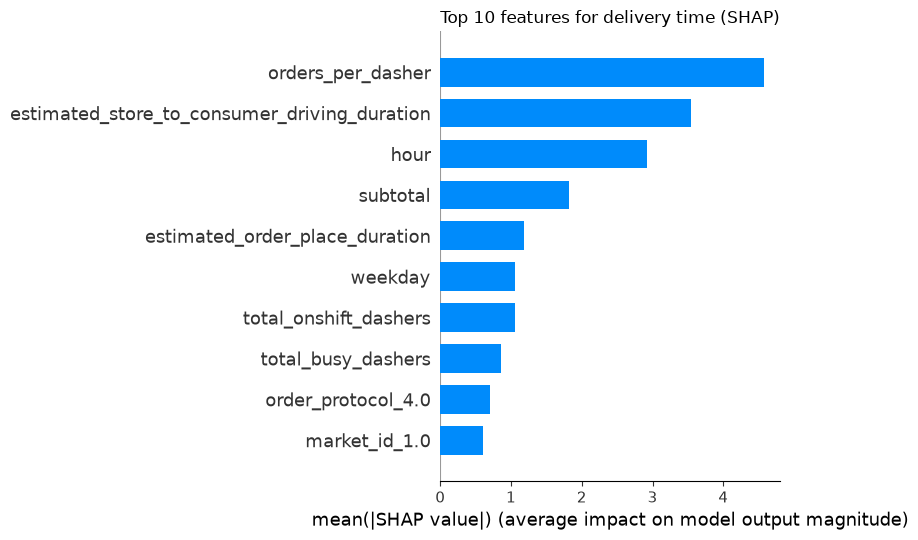

In [3]:
# bar plot: average size of the push of each feature
shap.summary_plot(shap_values, sample, plot_type="bar", max_display=10, show=False)
plt.title("Top 10 features for delivery time (SHAP)")
plt.tight_layout()
plt.savefig("../reports/13_shap_bar.png", dpi=150)
plt.show()

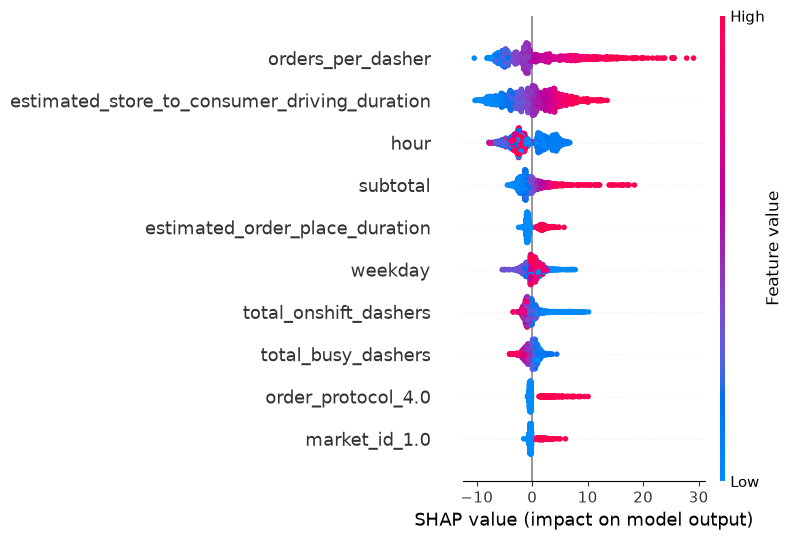

In [4]:
# dots: each dot is one order; color = feature value (red high, blue low)
shap.summary_plot(shap_values, sample, max_display=10, show=False)
plt.tight_layout()
plt.savefig("../reports/14_shap_dots.png", dpi=150)
plt.show()

In [5]:
# Example
i = 0
base = explainer.expected_value                      # average prediction
base = float(np.ravel(base)[0])
pred_i = eta_model.predict(sample.iloc[[i]])[0]
print("average prediction:", round(base, 1), "min")
print("this order:", round(pred_i, 1), "min")

# 5 biggest pushes
push = pd.Series(shap_values[i], index=sample.columns)
print(push.reindex(push.abs().sort_values(ascending=False).index).head(5).round(2))

average prediction: 47.1 min
this order: 70.0 min
estimated_store_to_consumer_driving_duration    6.01
subtotal                                        4.69
hour                                            4.46
store_primary_category_dessert                  3.32
estimated_order_place_duration                  3.29
dtype: float64


In [6]:
words = {
    "orders_per_dasher": "many orders waiting for each driver",
    "busy_ratio": "most drivers are busy",
    "available_dashers": "few free drivers",
    "total_outstanding_orders": "many open orders",
    "total_onshift_dashers": "number of drivers on shift",
    "total_busy_dashers": "number of busy drivers",
    "estimated_store_to_consumer_driving_duration": "long drive to the customer",
    "estimated_order_place_duration": "slow order handling at the store",
    "subtotal": "large order value",
    "total_items": "many items in the order",
    "max_item_price": "expensive item in the order",
    "hour": "busy time of day",
}

def reasons(row_shap, columns, n=3):
    # features that pushed the time UP, biggest first
    push = pd.Series(row_shap, index=columns)
    top = push[push > 0].sort_values(ascending=False).head(n)
    return [words.get(name, name.replace("_", " ")) for name in top.index]

print(reasons(shap_values[0], sample.columns))

['long drive to the customer', 'large order value', 'busy time of day']


c:\Projects\eta-engine\venv\Lib\site-packages\shap\explainers\_tree.py:578: UserWarning: LightGBM binary classifier with TreeExplainer shap values output has changed to a list of ndarray
  warnings.warn(


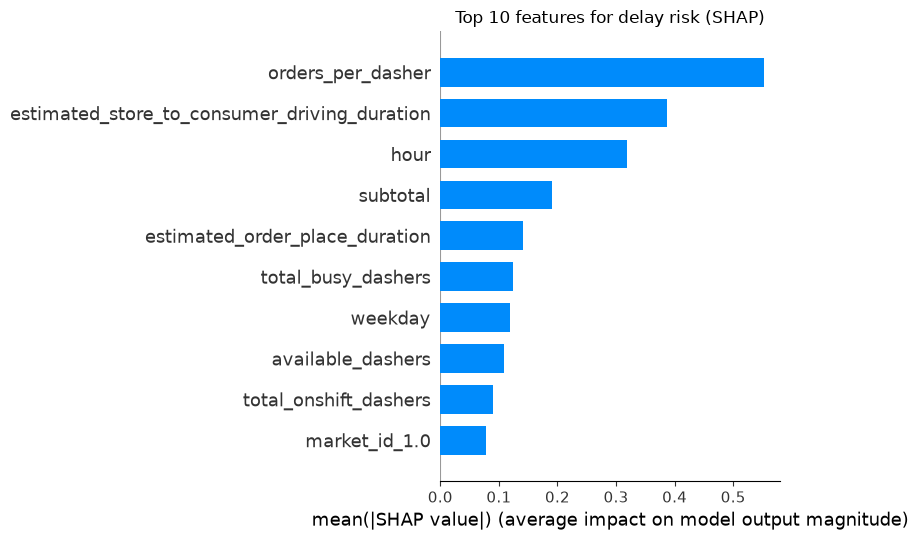

In [7]:
# same idea for the delay chance
exp_clf = shap.TreeExplainer(clf)
sv = exp_clf.shap_values(sample)
if isinstance(sv, list):          
    sv = sv[1]

shap.summary_plot(sv, sample, plot_type="bar", max_display=10, show=False)
plt.title("Top 10 features for delay risk (SHAP)")
plt.tight_layout()
plt.savefig("../reports/15_shap_delay.png", dpi=150)
plt.show()

In [8]:
# test results table
pred = eta_model.predict(X_test)
res = pd.DataFrame({"real": y_test.values, "pred": pred})
res["error"] = res["pred"] - res["real"]          # negative = we guessed too low
res["abs_error"] = res["error"].abs()
res["hour"] = X_test["hour"].values
res["drive_min"] = X_test["estimated_store_to_consumer_driving_duration"].values / 60
res["busy_ratio"] = X_test["busy_ratio"].values

print("average error (negative = guessing too low):", round(res["error"].mean(), 2))

# MAE by real delivery speed
res["speed"] = pd.cut(res["real"], [0, 35, 45, 56, 75, 200],
                      labels=["very fast", "fast", "normal", "slow", "very slow"])
print(res.groupby("speed", observed=True)["abs_error"].agg(["mean", "count"]).round(2))

# MAE by driving time group
res["drive_group"] = pd.qcut(res["drive_min"], 4)
print(res.groupby("drive_group", observed=True)["abs_error"].mean().round(2))

# MAE by hour (only hours with enough orders)
by_hour = res.groupby("hour")["abs_error"].agg(["mean", "count"])
print(by_hour[by_hour["count"] >= 500].round(2))

average error (negative = guessing too low): -1.38
            mean  count
speed                  
very fast  10.38   8636
fast        7.05  10055
normal      7.10   9082
slow       11.60   8097
very slow  30.82   3587
drive_group
(-0.001, 6.417]     10.52
(6.417, 9.1]        10.98
(9.1, 11.817]       10.96
(11.817, 24.333]    11.08
Name: abs_error, dtype: float64
       mean  count
hour              
0      9.75   2616
1     10.93   5610
2     11.84   7209
3     11.74   5262
4     10.74   3373
5     10.87   1638
17    11.36    704
18    10.08   1005
19    11.21   2543
20     9.93   2998
21     9.32   2234
22     9.74   1771
23    10.50   1602


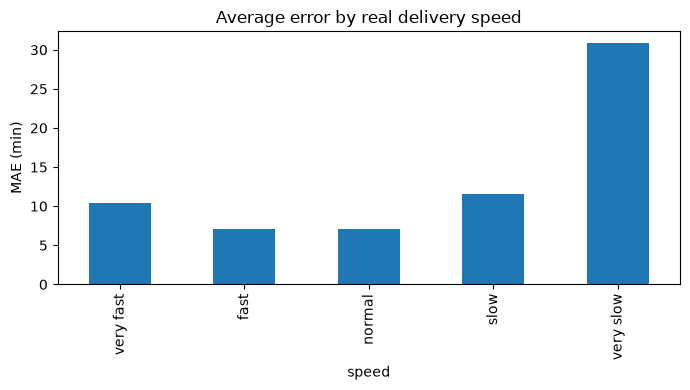

In [9]:
res.groupby("speed", observed=True)["abs_error"].mean().plot(kind="bar", figsize=(7, 4))
plt.title("Average error by real delivery speed")
plt.ylabel("MAE (min)")
plt.tight_layout()
plt.savefig("../reports/16_error_by_speed.png", dpi=150)
plt.show()

In [10]:
joblib.dump(words, "../models/reason_words.pkl")
print("saved")

saved


## Day 5 Findings
1. Top drivers of delivery time (SHAP): orders per dasher, driving duration and hour of day.
2. Heavy driver load pushes delivery time up the most (up to about 28 min); a long drive adds up to about 13 min.
3. The delay classifier relies on the same top features: orders per dasher, driving duration and hour of day.
4. More drivers on shift push delivery time down.
5. The model guesses 1.4 min too low on average, because the test weeks were slower.
6. Errors are about 7 min for normal and fast orders, but 30.8 min for very slow ones, so the model misses extreme delays.
7. Error is highest at hours 2 and 3 UTC (about 11.8 min) and similar across driving-time groups.